<a href="https://colab.research.google.com/github/TRACE-Structures/digital_twinning/blob/main/demo/notebooks/hybrid_pilot_Palisaden_example.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Tall Timber Building with Bayesian Digital Twinning**  

This framework demonstrates **Bayesian Digital Twinning** for an eight-storey **cross-laminated timber (CLT) building**. The model dynamically updates structural parameters using experimental modal data to refine predictions and quantify uncertainties.  

### **System Overview**  
The building’s dynamic behavior is governed by eigenfrequencies from a finite element (FE) model.

### **Probabilistic Framework**  
A **Bayesian inversion** updates parameters using experimental modal data (frequencies). The workflow includes:  
1. **Surrogate Modeling**: A generalized Polynomial Chaos (gPC) expansion replaces costly FE simulations, approximating eigenfrequencies as functions of parameters.  
2. **Mode Tracking**: k-means clustering partitions mode shapes to address mode-switching issues, ensuring consistent pairing between numerical and experimental modes.  
3. **Uncertainty Quantification**: Sobol indices identify influential parameters, while posterior distributions reflect updated confidence in stiffness and mass values.  

### **Key Innovations**  
- **Hybrid Data Integration**: Combines forced vibration test data (FRFs) with FE-derived modal properties.  
- **Error Modeling**: Accounts for measurement noise and modeling approximations.  

### **Visualizations & Results**  
- **Eigenfrequency Distributions**: Prior vs. posterior uncertainties (e.g., Mode 1: 2.77±0.18 Hz → 2.84±0.01 Hz).  
- **MAC Matrix**: Modal Assurance Criterion highlights correlations between experimental and numerical mode shapes.  

<div style="text-align: center;">
    <img src="https://raw.githubusercontent.com/TRACE-Structures/digital_twinning/main/demo/data/Palisaden_building/Palisaden.png" alt="Palisaden Building" width="580">
</div>  

### **Conclusion**  
The Bayesian digital twin provides a **probabilistic FE model** that aligns with experimental data while quantifying uncertainties. It reveals as-built stiffness reductions in joints and validates timber as a viable material for tall structures. This approach bridges gaps in traditional deterministic methods, offering actionable insights for vibration serviceability assessments.

# Imports

In [ ]:
! pip install digital_twinning

In [2]:
from uncertain_variables import *
import digital_twinning as dt
import pandas as pd

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Generate data

## Define Variables and VariableSet

In [3]:
P1 = Variable('COEF_VERT', UniformDistribution(0.5, 1))
P2 = Variable('COEF_G', UniformDistribution(1, 3))
P3 = Variable('FACADE', UniformDistribution(1, 1.5))
P4 = Variable('FOUNDATION', UniformDistribution(7, 10))
P5 = Variable('WEIGHT', UniformDistribution(0.8, 1.2))

Q = VariableSet()
Q.add(P1)
Q.add(P2)
Q.add(P3)
Q.add(P4)
Q.add(P5)

## Sampling
Sampling is already made. We just read the sample points from a file.

In [4]:
data_path = 'https://raw.githubusercontent.com/TRACE-Structures/digital_twinning/main/demo/data/Palisaden_building/'
Q_df = pd.read_csv(data_path + 'x_df.csv')

Output data from FEM solver

In [5]:
QoI_df = pd.read_csv(data_path + 'y_df.csv')
QoI_names = QoI_df.columns.to_list()

# Model

## **Choosing the Model**

In this notebook, we implement the model using one of the following methods: **gPCE**, **DNN**, or **GBT**.

- **gPCE (Generalized Polynomial Chaos Expansion)**: Models uncertainty by expressing the output as a polynomial expansion, with coefficients determined by projecting the system's response onto orthogonal polynomials.

- **DNN (Deep Neural Networks)**: Machine learning models composed of interconnected neurons, capable of learning complex, non-linear patterns from data.

- **GBT (Gradient Boosting Trees)**: Combines weak decision trees into a strong predictive model, iteratively correcting errors from previous trees for robust performance.


In [6]:
method = "gPCE"

In [ ]:
# Model configurations
match method:
    # Deep Neural Network (DNN) model configurations
    case "DNN":
        layers = [{'neurons': 512, 'activation': 'relu', 'dropout': 0.2},
                  {'neurons': 256, 'activation': 'sigmoid', 'dropout': 0.2},
                  {'neurons': 256, 'activation': 'sigmoid', 'dropout': 0.2},
                  {'neurons': 128, 'activation': 'relu', 'dropout': None}]
        outputAF = 'tanh'
        model = dt.DNN(Q,
                            QoI_names,
                            layers=layers,
                            outputAF=outputAF
                            )
    # Generalized Polynomial Chaos Expansion (gPCE) model configurations
    case "gPCE":
        p = 4
        k_fold = 9
        model = dt.gPCE(Q,
                             QoI_names,
                             p=p
                             )
    # Gradient Boosted Trees (GBT) model configurations
    case "GBT":
        max_depth = 6
        num_of_iter = 250
        k_fold = 9
        model = dt.GBT(Q,
                            QoI_names,
                            max_depth=max_depth,
                            num_of_iter=num_of_iter)
    # Linear Regression model configurations
    case "LinReg":
        model = dt.LinReg(Q,
                              QoI_names
                              )

    # Default case for unsupported methods
    case _:
        raise ValueError(f"Unsupported method: {method}")

Set configurations

In [8]:
train_test_ratio = 0.8
random_seed = 1997
split_type = 'no_shuffle'

X_train, X_test, y_train, y_test = model.train_test_split(Q_df, QoI_df, train_test_ratio=train_test_ratio, random_seed=random_seed, split_type=split_type)

## Define model

In [9]:
match method:
    case "DNN":
        optimizer = 'Adam'
        loss = 'MSE'
        epochs = 100
        batch_size = 32
        k_fold = None
        early_stopping = {
            'patience': 25,
            'min_delta': 0.0001
        }
        model.train(X_train, y_train, optimizer=optimizer, loss=loss, epochs=epochs, batch_size=batch_size, k_fold=k_fold, early_stopping=early_stopping)
    case "LinReg":
        model.train(X_train, y_train)
    case _:
        model.train(X_train, y_train, k_fold=k_fold)

----- Training started for 'gPCEModel' model -----
Fold 1/9
Fold 2/9
Fold 3/9
Fold 4/9
Fold 5/9
Fold 6/9
Fold 7/9
Fold 8/9
Fold 9/9
Average train loss: 0.00000378121401, Average valid loss: 0.00000396570308
----- Training ended for gPCEModel model -----


In [10]:
# get mean and variance of surrogate model
mean, var = model.get_mean_and_var()
mean, var

(array([1.98556342, 2.61848616, 2.97562077, 6.70255641]),
 array([0.05376343, 0.10411756, 0.13520618, 0.56561478]))

In [11]:
model.model.mean()

array([1.99250114, 2.62538268, 2.98123802, 6.71040215])

## Calculate Sobol Sensitivities

In [12]:
# set max_index for Sobol sensitivity analysis
max_index = 2

partial_variance, sobol_index = model.get_sobol_sensitivity(max_index)

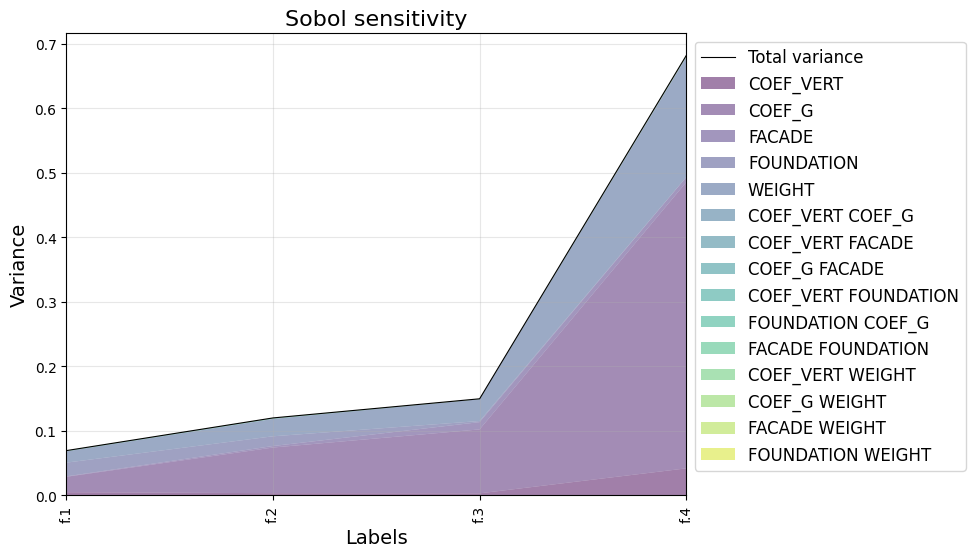

In [13]:
# Plot Sobol Sensitivity Index
# The 'plot_sobol_sensitivity' method generates a plot of Sobol Sensitivity indices, which quantify
# the contribution of each input parameter to the output uncertainty.
# - max_index: Specifies the maximum index of parameters to consider in the plot.
fig = model.plot_sobol_sensitivity(y_train, max_index=max_index)

## Calculate SHAP values

In [14]:
# 1 point from the data
q_sample_df = X_test.iloc[100:101]

In [15]:
# Calculate SHAP (Shapley Additive Explanations) values
# The 'get_shap_values' method computes the SHAP values for the model's test data (model.X_test).
# SHAP values explain the contribution of each input feature to the prediction for each test sample.
# - model.X_test.iloc[:100]: The first 100 samples from the test set are selected for SHAP value computation.
# SHAP values help to interpret the model's decisions and understand the impact of each input parameter on the output.
shap_values = await model.get_shap_values(X_test.iloc[:100], silent=True)


Message: sample size for shap values is set to 100.


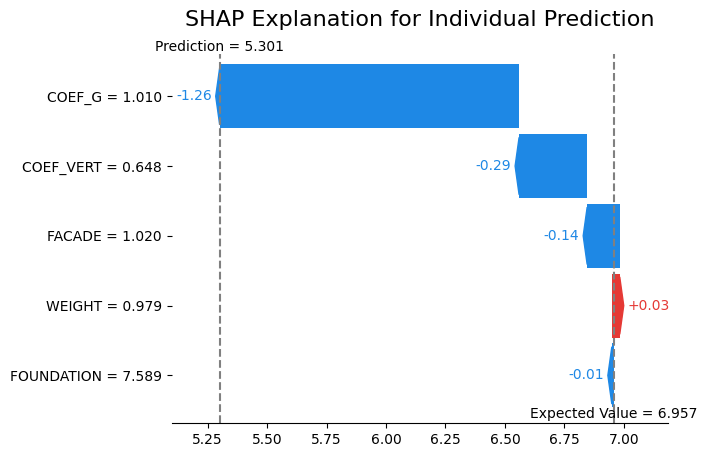

In [16]:
# Plot SHAP Single Waterfall Plot
# The 'plot_shap_single_waterfall' method generates a SHAP waterfall plot for a single test sample,
# visualizing how each feature contributes to the model's prediction for that sample.
# - q_sample_df: A DataFrame containing the sample data (e.g., a specific parameter set) for which the SHAP values are calculated.
# - param_name: The name of the quantity of interest (QoI) being analyzed ('f.4' in this case).
# The SHAP waterfall plot shows the cumulative effect of each feature on the model's prediction, helping to interpret individual predictions.
fig = await model.plot_shap_single_waterfall(X_test, silent=True, q=q_sample_df, param_name='f.4')

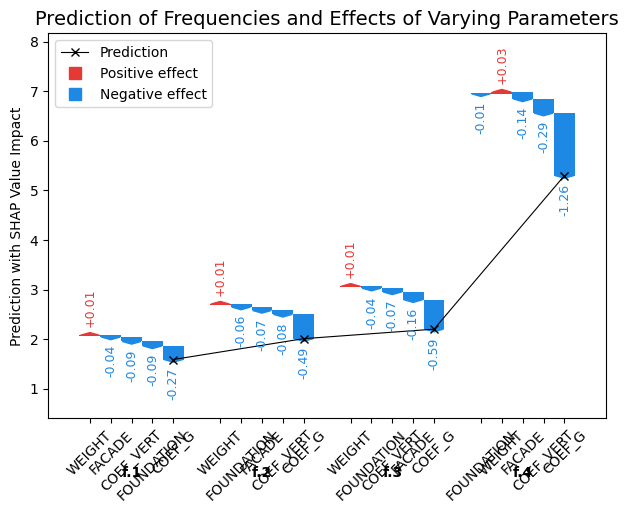

In [17]:
# Generate SHAP (Shapley values) waterfall plots for multiple features
# 'q_sample_df' contains the uncertain parameters sample, which will be passed as input to the SHAP model.
# The 'plot_shap_multiple_waterfalls' function will generate individual waterfall plots

fig = await model.plot_shap_multiple_waterfalls(X_test, silent=True, q=q_sample_df, param_name='freq')

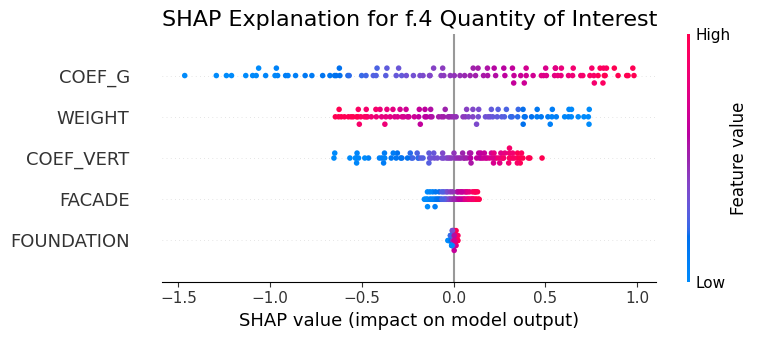

In [19]:
# Plot SHAP Beeswarm Plot
# The 'plot_shap_beeswarm' method generates a SHAP beeswarm plot, which visualizes the distribution of SHAP values
# for a range of test samples, showing the impact of each feature on the model’s predictions.
# - q: The test data (model.X_test.iloc[:100]) is selected for which SHAP values are calculated and visualized.
# - param_name: The name of the quantity of interest (QoI) for which SHAP values are computed ('f.4' in this case).
# The SHAP beeswarm plot shows how different input features influence the predictions across multiple samples,
# helping to understand the global feature importance and the relationships between features and the target.
fig = await model.plot_shap_beeswarm(X_test, silent=True, q=X_test.iloc[:100], param_name='f.4')

In [20]:
# Make a prediction using the surrogate model
# - q_sample_df: A DataFrame containing the input parameter values for which the model will generate a prediction.
model.predict(q_sample_df)

array([[1.5910933 , 2.01139886, 2.20316954, 5.30092061]])

# Update

## Synthetic measurement

In [21]:
qoi_m_df = pd.read_csv('palisaden_z_m_df.csv') # The measurement of this building is not public.
                                     # The 'z_m_df.csv' file is only a placeholder in this notebook

## Set parameters

In [22]:
# For Update
sigma = pd.read_csv('palisaden_sigma.csv') # The std of the measurement of this building is not public.
                                 # The 'sigma.csv' file is only a placeholder in this notebook

# Generate the simulation parameter set (random noise) based on the updated measurement error (sigma)
E = generate_stndrn_variable_set(sigma.values.flatten())

nwalkers = 64  # Number of walkers (parallel chains) in the MCMC process
nburn = 1000  # Number of burn-in steps: these are discarded, as they help the MCMC chain reach equilibrium
niter = 100  # Total number of iterations for the MCMC process

In [23]:
# Initialize the Digital Twin model with the surrogate model and simulation parameter set (E)
DT = dt.DigitalTwin(model, E)  # Create a DigitalTwin instance that integrates the surrogate model and the random noise (E)

In [24]:
# Update the Digital Twin model with the synthetic measurement data and run MCMC sampling
DT.update(qoi_m_df, nwalkers=nwalkers, nburn=nburn, niter=niter)
# The 'update' method updates the Digital Twin using the synthetic measurement data (qoi_m_df)
# and performs MCMC sampling with the specified parameters (number of walkers, burn-in steps, and iterations)

MCMC creating
Burning period


100%|██████████| 1000/1000 [01:28<00:00, 11.35it/s]


MCMC running


100%|██████████| 100/100 [00:09<00:00, 10.56it/s]

--- 97.71569967269897 seconds ---


In [25]:
# Get the posterior mean and variance from the Digital Twin model
mean_of_post, variance_of_post = DT.get_mean_and_var_of_posterior()
# This returns the mean and variance of the posterior distribution after updating the model with data.

# Get the Maximum A Posteriori (MAP) estimate of the parameters
map = DT.get_MAP()
# This retrieves the most likely parameter values based on the updated model.

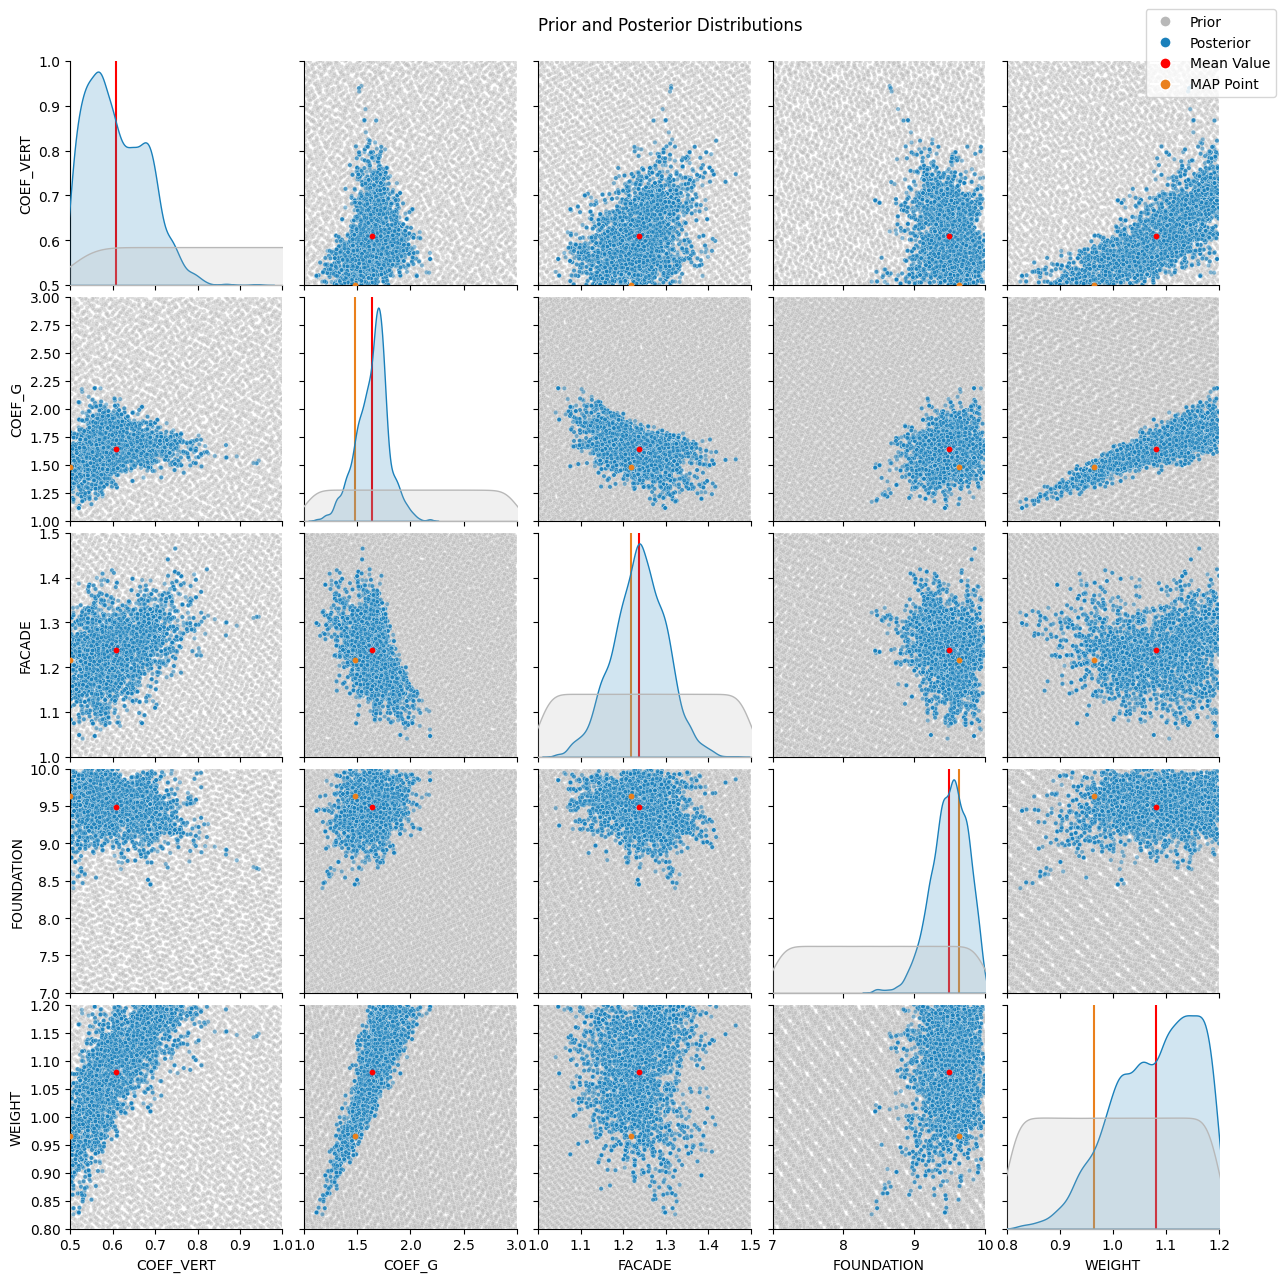

In [27]:
# Plot the MCMC sampling results along with the mean and MAP values
fig = DT.plot_MCMC(X_train)

In [28]:
model.save_model('Palisaden_model', '')  # Save the trained surrogate model to a file

Model saved to Palisaden_model.sm
